# Phân tích mức tiêu hao nhiên liệu

## 1. ĐỌC DỮ LIỆU

Dữ liệu `mpg.csv` gồm các thông tin như sau:

- **mpg**: Miles/(US) gallon số gallon xăng trên 1 dặm
- **cylinders:** số lượng xilanh
- **displacement:**  Displacement/ dung tích xilanh (cu.in / $inches^3$)
- **horsepower:** công suất theo mã lực
- **weight:** trọng lượng (pound)
- **acceleration:** Gia tốc
- **model_year:** Năm sản xuất
- **origin:** Xuất xứ
- **name:** Tên dòng xe


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("mpg.csv")

# Hiển thị 5 dòng đầu tiên
df.head(5)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 2. TÌM HIỂU DỮ LIỆU

### 2.1 Kiểm tra có dòng nào không có dữ liệu?

In [5]:
# Kiểm tra số lượng giá trị thiếu ở từng cột
df.isnull().sum()
# Nếu muốn tìm các dòng có ít nhất một giá trị thiếu:
# df[df.isnull().any(axis=1)]

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

### 2.2 Xóa các dòng không có dữ liệu


In [6]:
df = df.dropna()

### 2.3 Tìm trung binh, trung vị của các thuộc tính: 'cylinders', 'horsepower', 'weight'

In [8]:
print(df[['cylinders', 'horsepower', 'weight']].mean()) #trung bình
print(df[['cylinders', 'horsepower', 'weight']].median()) #trung vị 

cylinders        5.471939
horsepower     104.469388
weight        2977.584184
dtype: float64
cylinders        4.0
horsepower      93.5
weight        2803.5
dtype: float64


### 2.4 Tìm miền giá trị và miền phân vị của thuộc tính 'mpg'

In [10]:
# Miền giá trị của mpg
df["mpg"].min(), df["mpg"].max()
# Khoảng biến thiên
df["mpg"].max() - df["mpg"].min()
# Các phân vị của mpg
df["mpg"].quantile([0, 0.25, 0.5, 0.75, 1])

0.00     9.00
0.25    17.00
0.50    22.75
0.75    29.00
1.00    46.60
Name: mpg, dtype: float64

## 3. SO SÁNH MỨC TIÊU HAO NHIÊN LIỆU TRUNG BÌNH CỦA CÁC DÒNG XE DỰA TRÊN XUẤT XỨ

So sánh mức tiêu hao nhiên liệu trung bình của các dòng xe Mỹ, Nhật và Châu Âu

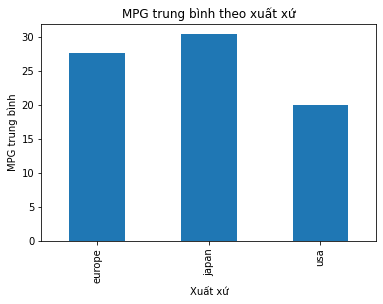

In [11]:
df.groupby('origin')['mpg'].mean().plot(kind='bar')

plt.xlabel('Xuất xứ')
plt.ylabel('MPG trung bình')
plt.title('MPG trung bình theo xuất xứ')
plt.show()

## 4. VẼ HISTOGRAM TRỌNG LƯỢNG CÁC XE

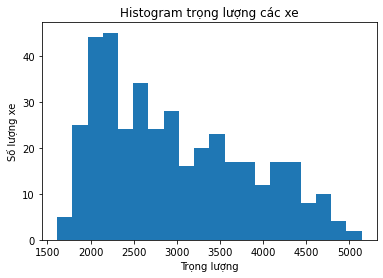

In [12]:
plt.hist(df['weight'], bins=20)

plt.xlabel('Trọng lượng')
plt.ylabel('Số lượng xe')
plt.title('Histogram trọng lượng các xe')
plt.show()

## 5. TÍNH TỶ LỆ CÁC DÒNG XE DỰA TRÊN XUẤT XỨ

usa       62.500000
japan     20.153061
europe    17.346939
Name: origin, dtype: float64


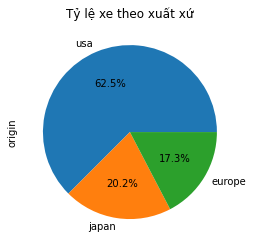

In [13]:
print(df['origin'].value_counts(normalize=True) * 100)
df['origin'].value_counts().plot(kind='pie', autopct='%1.1f%%')

plt.title('Tỷ lệ xe theo xuất xứ')
plt.show()

## 6. VẼ BOXPLOT SO SÁNH CÔNG SUẤT CỦA CÁC DÒNG XE THẬP NIÊN 70, 80

Lưu ý: Các dòng xe thập niên 70 (1970 - 1979), thập niên 80 (1980 - 1989)

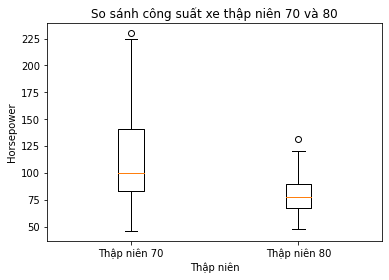

In [14]:
xe70 = df[(df['model_year'] >= 70) & (df['model_year'] <= 79)]

xe80 = df[(df['model_year'] >= 80) & (df['model_year'] <= 89)]
data = [xe70['horsepower'], xe80['horsepower']]
plt.boxplot(data, labels=['Thập niên 70', 'Thập niên 80'])

plt.xlabel('Thập niên')
plt.ylabel('Horsepower')
plt.title('So sánh công suất xe thập niên 70 và 80')
plt.show()

## 7. KHẢO SÁT MỨC TIÊU HAO NHIÊN LIỆU

### 7.1 Với số lượng xi lanh

Thử vẽ bằng đồ thị scatter plot.

In [ ]:

plt.scatter(df['cylinders'], df['mpg'])

plt.xlabel('Số lượng xi lanh')
plt.ylabel('MPG')
plt.title('MPG và số lượng xi lanh')
plt.show()

### 7.2 Với công suất theo mã lực

In [ ]:
plt.scatter(df['horsepower'], df['mpg'])

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('MPG và công suất')
plt.show()

### 7.3 Với gia tốc

In [ ]:
plt.scatter(df['acceleration'], df['mpg'])

plt.xlabel('Acceleration')
plt.ylabel('MPG')
plt.title('MPG và gia tốc')
plt.show()

### 7.4 Với năm sản xuất

In [ ]:
plt.scatter(df['model_year'], df['mpg'])

plt.xlabel('Năm sản xuất')
plt.ylabel('MPG')
plt.title('MPG và năm sản xuất')
plt.show()